In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset

print("Libraries imported successfully")

/Users/shreyaakhade/Documents/UniversityProjects/healthcheck-nlp/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully


In [2]:
from datasets import load_dataset

dataset = load_dataset("ImperialCollegeLondon/health_fact", trust_remote_code=True)
print(dataset)

Generating validation split: 100%|██████████| 1225/1225 [00:00<00:00, 27716.31 examples/s]

DatasetDict({
    train: Dataset({
        features: ['claim_id', 'claim', 'date_published', 'explanation', 'fact_checkers', 'main_text', 'sources', 'label', 'subjects'],
        num_rows: 9832
    })
    test: Dataset({
        features: ['claim_id', 'claim', 'date_published', 'explanation', 'fact_checkers', 'main_text', 'sources', 'label', 'subjects'],
        num_rows: 1235
    })
    validation: Dataset({
        features: ['claim_id', 'claim', 'date_published', 'explanation', 'fact_checkers', 'main_text', 'sources', 'label', 'subjects'],
        num_rows: 1225
    })
})


In [3]:
print(dataset.keys())

dict_keys(['train', 'test', 'validation'])


In [4]:
print(dataset["train"][0])

{'claim_id': '15661', 'claim': '"The money the Clinton Foundation took from from foreign governments while Hillary Clinton was secretary of state ""is clearly illegal. … The Constitution says you can’t take this stuff."', 'date_published': 'April 26, 2015', 'explanation': '"Gingrich said the Clinton Foundation ""took money from from foreign governments while (Hillary Clinton) was secretary of state. It is clearly illegal. … The Constitution says you can’t take this stuff."" A clause in the Constitution does prohibit U.S. officials such as former Secretary of State Hillary Clinton from receiving gifts, or emoluments, from foreign governments. But the gifts in this case were donations from foreign governments that went to the Clinton Foundation, not Hillary Clinton. She was not part of the foundation her husband founded while she was secretary of state. Does that violate the Constitution? Some libertarian-minded constitutional law experts say it very well could. Others are skeptical. Wha

In [6]:
train_df = dataset["train"].to_pandas()

print(train_df.head())

  claim_id                                              claim  \
0    15661  "The money the Clinton Foundation took from fr...   
1     9893    Annual Mammograms May Have More False-Positives   
2    11358  SBRT Offers Prostate Cancer Patients High Canc...   
3    10166  Study: Vaccine for Breast, Ovarian Cancer Has ...   
4    11276  Some appendicitis cases may not require ’emerg...   

       date_published                                        explanation  \
0      April 26, 2015  "Gingrich said the Clinton Foundation ""took m...   
1    October 18, 2011  This article reports on the results of a study...   
2  September 28, 2016  This news release describes five-year outcomes...   
3    November 8, 2011  While the story does many things well, the ove...   
4  September 20, 2010  We really don’t understand why only a handful ...   

                                       fact_checkers  \
0                                      Katie Sanders   
1                                       

In [7]:
print(train_df.columns.tolist())

['claim_id', 'claim', 'date_published', 'explanation', 'fact_checkers', 'main_text', 'sources', 'label', 'subjects']


In [8]:
print("Training records:", len(dataset["train"]))
print("Validation records:", len(dataset["validation"]))
print("Test records:", len(dataset["test"]))

Training records: 9832
Validation records: 1225
Test records: 1235


In [9]:
print(train_df.isnull().sum())

claim_id          0
claim             0
date_published    0
explanation       0
fact_checkers     0
main_text         0
sources           0
label             0
subjects          0
dtype: int64


In [10]:
train_df = train_df.copy()

train_df = train_df.dropna(subset=["claim", "label"])

print("Records after removing missing claims or labels:")
print(len(train_df))

Records after removing missing claims or labels:
9832


In [11]:
print(train_df["label"].value_counts(dropna=False))

label
 2    5078
 0    3001
 1    1434
 3     291
-1      28
Name: count, dtype: int64


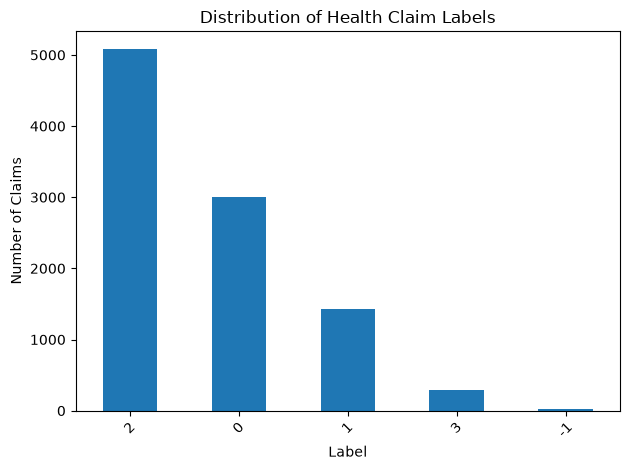

In [12]:
label_counts = train_df["label"].value_counts()

label_counts.plot(kind="bar")

plt.title("Distribution of Health Claim Labels")
plt.xlabel("Label")
plt.ylabel("Number of Claims")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()